# CS4 - Making the Most of an Imperfect Well (16/7-1)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/case_studies/cs4_imperfect_well_recovery_16_7-1.ipynb)

**Petrophys Case Studies - the honesty & robustness study**

---

## 1. The brief

> *"Well 16/7-1 is the only log data we have over this fault block. It is old, and it is
> incomplete: there is no neutron log, no PEF, the deep resistivity reads thousands of ohm.m
> over a long section, and there are washout zones. Management still needs a defensible
> porosity and net-pay number to decide whether to carry this prospect forward. Give us the
> best interpretation you honestly can - and be explicit about which parts of it we can trust
> and which parts rest on assumptions."*

This is the situation every petrophysicist eventually faces: a real, imperfect well and a
decision that cannot wait for a perfect dataset. The professional answer is **not** to refuse,
and it is **not** to quietly paper over the gaps. It is to:

1. **Inventory** exactly what was measured and what is missing (a *data readiness* assessment).
2. **Flag** the detectable problems (resistivity beyond the tool's reliable range, a sonic on
   the wrong scale, washout) transparently - flagged out, not silently corrected - and find out
   *why* each one happens.
3. **Test** whether the gaps could be filled: validate an imputer on this well before trusting
   it, and decide what its output may be used for.
4. **Interpret** on the measured data, carrying an **uncertainty flag** on every interval that
   leans on suspect data.
5. **Deliver** a caveated answer that a reviewer can audit line by line.

The deliverable is a **data readiness report** (measured, flagged, missing) plus a **caveated
net-pay result** that is honest about which parts rest on suspect data and assumptions.

### How this differs from CS1-CS3
CS1 evaluated a well with a full log suite, core and a documented Rw; CS2 and CS3 had
core-derived curves and near-complete suites. CS4 has none of that luxury. The emphasis here is entirely on **QC, imputation, validation and
uncertainty communication** - the parts of the job that separate a defensible interpretation
from a dangerous one. We reference the interpretation mechanics taught in the Part A/B tutorials
rather than re-deriving them.

### What you will learn

- How to build a data-readiness table against a standard log suite.
- How to flag out-of-range resistivity and washouts instead of silently correcting them - and how
  to tell a real rock response (evaporites) from a tool problem.
- How to catch a curve stored on the wrong scale before it feeds a model.
- How to validate an imputer with a hold-out (blank-and-restore) test before trusting it - and what
  that test does *not* tell you.
- How to split net pay into firm and uncertain parts, with every assumption stated.

### Prerequisites

Lessons 02 (QC and standardization), 04 (porosity), 07 (water saturation) and **13 (ML curve
imputation)**. This case study needs the optional ML extra (scikit-learn, used by
`pp.impute`) in the notebook kernel:

```bash
python -m pip install -e ".[ml]"      # from a repository checkout
# or: python -m pip install "petrophys[ml]"
```

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Setup

All data is bundled with the library - no external files. No warnings are silenced: the
interpretation and `pp.impute` report what they had to assume or could not trust, and those
warnings are part of the evidence.

In [2]:
import pandas as pd
import petrophys as pp
from petrophys.visualization import LITHOLOGY_CODE_LABELS

pd.set_option("display.precision", 3)
pp.list_samples("geolink")

['15_9-14', '16_7-1', '25_5-1', '30_6-5']

## 2. The well & data - a first look

**16/7-1** is a North Sea well of the GeoLink dataset, logged in metres. Let us load it and see
exactly what curves survived digitisation, and how much of the hole each one covers.

In [3]:
well = pp.read(pp.sample("16_7-1"))
readiness = pd.DataFrame(well.describe()["curves"]).sort_values("valid_fraction")
readiness

,mnemonic,unit,description,valid_fraction
11,RMED,ohm.m,RMED,0.474
5,RHOB,g/cm3,RHOB,0.532
4,DRHO,g/cm3,DRHO,0.532
7,DTC,us/ft,DTC,0.629
0,LITHOLOGY_GEOLINK,_,Lithology_geolink,0.697
8,RDEP,ohm.m,RDEP,0.986
6,GR,gAPI,GR,0.992
10,RSHA,ohm.m,RSHA,0.997
2,CALI,in,CALI,1.000
1,DCAL,in,DCAL,1.000


Twelve curves. Three things jump out immediately for anyone who has done a formation
evaluation:

- There is a **GR, RHOB, DTC (sonic), SP and a full resistivity suite (RDEP/RMED/RSHA)** - a
  workable backbone.
- There is **no NPHI (neutron)** and **no PEF**. The neutron-density crossplot - the workhorse
  for porosity and gas detection - is off the table: porosity has to stand on the density log.
- There is a **CALI, BS and DCAL** (differential caliper), which is exactly what we need to
  find washout.

Before trusting any of it, we look at the coverage and the values.

## 3. Workflow plan

The order below is deliberate - each step de-risks the next:

| # | Step | Why here |
|---|------|----------|
| 1 | **Data readiness**: coverage and value range per curve | Know the gaps before touching the data |
| 2 | **Sonic on the wrong scale?** DTC against the lithology log | A mis-scaled input poisons whatever uses it |
| 3 | **RDEP above the tool's reliable range**: value-range QC, explained by lithology | Readings above 2000 ohm.m cannot feed Sw; here they mark the Zechstein evaporites |
| 4 | **Washout**: `detect_washout` from CALI-BS and DRHO | Flag intervals where RHOB (and thus porosity) is unreliable |
| 5 | **Test the imputer**: hold-out prediction of the *measured* RHOB with `pp.impute` | Never trust a gap-filled curve you have not error-checked on real data |
| 6 | **Interpret** with `pp.interpret` on the measured curves, assumptions stated | The actual evaluation |
| 7 | **Net pay with uncertainty flags**: firm against washout-flagged pay | The caveated deliverable |

The golden rule threaded through all of it: **anything derived from a suspect or modelled curve
inherits that curve's uncertainty**, and we track that explicitly.

## 4. Execution

### 4.1 Data readiness - coverage and value range per curve

A curve can be *present* in the LAS header but still be mostly null. The table above gives each
curve's valid-sample fraction; the chart is the first deliverable figure.

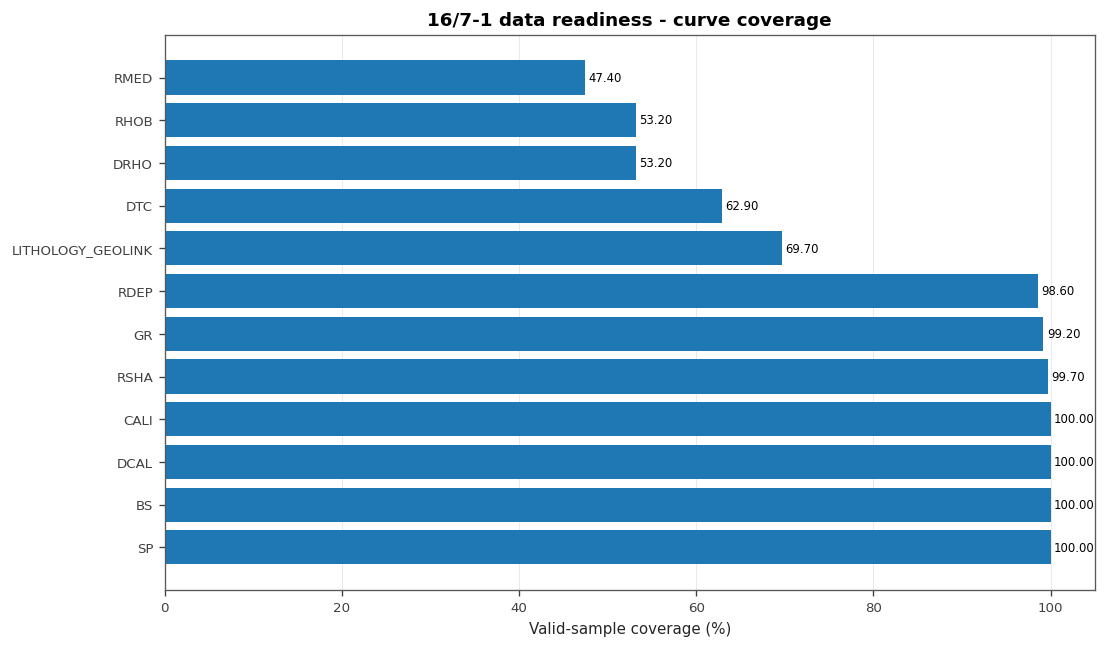

In [4]:
pp.bar_chart(readiness["mnemonic"], 100 * readiness["valid_fraction"], horizontal=True,
             value_labels=True, xlabel="Valid-sample coverage (%)",
             title="16/7-1 data readiness - curve coverage");

Coverage is half the story; the values are the other half:

In [5]:
well.to_dataframe().describe().T[["count", "min", "50%", "max"]]

,count,min,50%,max
DEPTH,14986.0,367.942,1509.799,2651.656
LITHOLOGY_GEOLINK,10452.0,2.000,7.000,22.000
DCAL,14986.0,-6.496,-0.043,12.036
CALI,14986.0,5.701,11.406,21.995
BS,14986.0,8.500,8.500,17.500
DRHO,7980.0,-0.066,0.000,0.089
RHOB,7980.0,1.732,2.087,2.961
GR,14871.0,1.225,52.672,117.510
DTC,9427.0,14.896,35.587,56.205
RDEP,14777.0,-0.023,1.195,4858.222


Reading coverage and values together:

- **NPHI and PEF: missing** - genuinely absent.
- **RMED, RHOB/DRHO and DTC: partial coverage** (47%, 53% and 63% of the hole) - recorded over
  only part of the well. RHOB and DRHO share the same coverage (same density tool run).
- **GR, RDEP, RSHA, CALI, BS, DCAL, SP: near-100%** - our backbone and QC curves.
- **RDEP max** runs to 4,858 ohm.m. That is far above anything a water- or oil-bearing
  clastic reads, but it is the *normal* response of evaporites: halite and anhydrite are almost
  perfect insulators. Section 4.3 shows that is what these readings are.
- **DTC range** is 14.9-56.2 us/ft. No rock is that fast: the matrix limits are about 43-55 us/ft
  (dolomite to quartz), halite reads about 67 us/ft and soft shallow mudstones well above
  100 us/ft. The next cell checks the scale.
- **SP min** is -6,183 mV - physically impossible (real SP anomalies are at most a few hundred mV).

### 4.2 Is the sonic on the right scale?

The well's own lithology log gives a test: the median DTC in each logged rock type, against the
textbook values.

In [6]:
logs = well.to_dataframe()
logs.groupby(logs["LITHOLOGY_GEOLINK"].map(LITHOLOGY_CODE_LABELS))["DTC"].median()

LITHOLOGY_GEOLINK
Anhydrite                 21.212
Argillaceous Limestone    31.776
Calcareous Cement         46.373
Chalk                     24.974
Cinerite                  40.910
Halite                    20.844
Sandy Silt                46.380
Shaly Silt                44.105
Silt                      48.712
Silty Sand                43.497
Silty Shale               43.229
Name: DTC, dtype: float64

**DTC is on the wrong scale.** Halite reads 20.8 us/ft against about 67 us/ft - about
0.31 times the expected value, roughly the factor 0.3048 of a feet/metres slip - and the silts and
silty shales read 43-49 us/ft where 100 us/ft or more is expected. It cannot be used as a sonic, and it
is rated **LOW** trust in the readiness report (6.1). The interpretation will reach the same
verdict on its own (4.6).

`pp.impute` uses every input log the well has, DTC included, and this study keeps that default
rather than hand-picking inputs. So treat the imputation result in this notebook - the
hold-out errors of 4.5 - as **contaminated by a mis-scaled input**. Exercise 3 asks you to
repeat the test without DTC.

### 4.3 Deep resistivity (RDEP) above the reliable range - detect, flag, explain

**Why this matters.** Archie's equation gives $S_w \propto \sqrt{R_w / (R_t\,\phi^m)}$. A deep
resistivity reading of thousands of ohm.m drives Archie $S_w$ towards zero whatever the rock is,
so such samples must not reach the saturation step unexamined. Above about 2000 ohm.m many
resistivity tools are also near or beyond the top of their reliable range, so the number itself is
uncertain.

The cause matters as much as the flag. In a clastic reservoir, isolated extreme readings may be a
tool problem. A long, continuous run of them usually is not: it is the true response of very
resistive rock. Evaporites (halite and anhydrite) have almost no conductive pore water, and the
16/7-1 well drilled the Zechstein salt in its lower part.

`apply_value_range_qc` carries a range for each curve family - **0.01-2000 ohm.m** for deep
resistivity, **-500 to +500 mV** for SP - and sets finite values outside it to NaN. Run on a copy of
the well, it gives the report: how many samples each rule would flag.

In [7]:
from petrophys.preprocessing import apply_value_range_qc

pd.DataFrame(apply_value_range_qc(pp.read(pp.sample("16_7-1")), ["RDEP", "RMED", "RSHA", "SP"]))

,curve,canonical_curve,low,high,action,changed,below,above
0,RDEP,RDEP,0.01,2000.0,nan,2954,4,2950
1,RMED,RDEP,0.01,2000.0,nan,3,3,0
2,RSHA,RXO,0.01,2000.0,nan,0,0,0
3,SP,SP,-500.00,500.0,nan,136,136,0


2,950 RDEP samples are above the range (and 4 at or below zero), and 136
impossible SP spikes. What rock are the high readings in? The well's own lithology log answers:

In [8]:
logs.query("RDEP > 2000")["LITHOLOGY_GEOLINK"].map(LITHOLOGY_CODE_LABELS).value_counts(dropna=False)

LITHOLOGY_GEOLINK
Halite       2579
NaN           314
Anhydrite      57
Name: count, dtype: int64

Almost every high reading lies in rock the lithology log codes as halite or anhydrite; the rest
(314 samples) has no code. The plot over the lower part of the well shows why: the
resistivity plateau of 2000 ohm.m and more (the RDEP scale is widened to 20,000 ohm.m) coincides with the halite and anhydrite of the lithology
track, and below the base of the coded halite (about 2570 m) the logs keep the same response - a
gamma ray of a few gAPI and a density near halite's. So these readings are **real evaporite resistivity, not a
tool fault**: they are beyond the tool's reliable range, and salt is not reservoir.

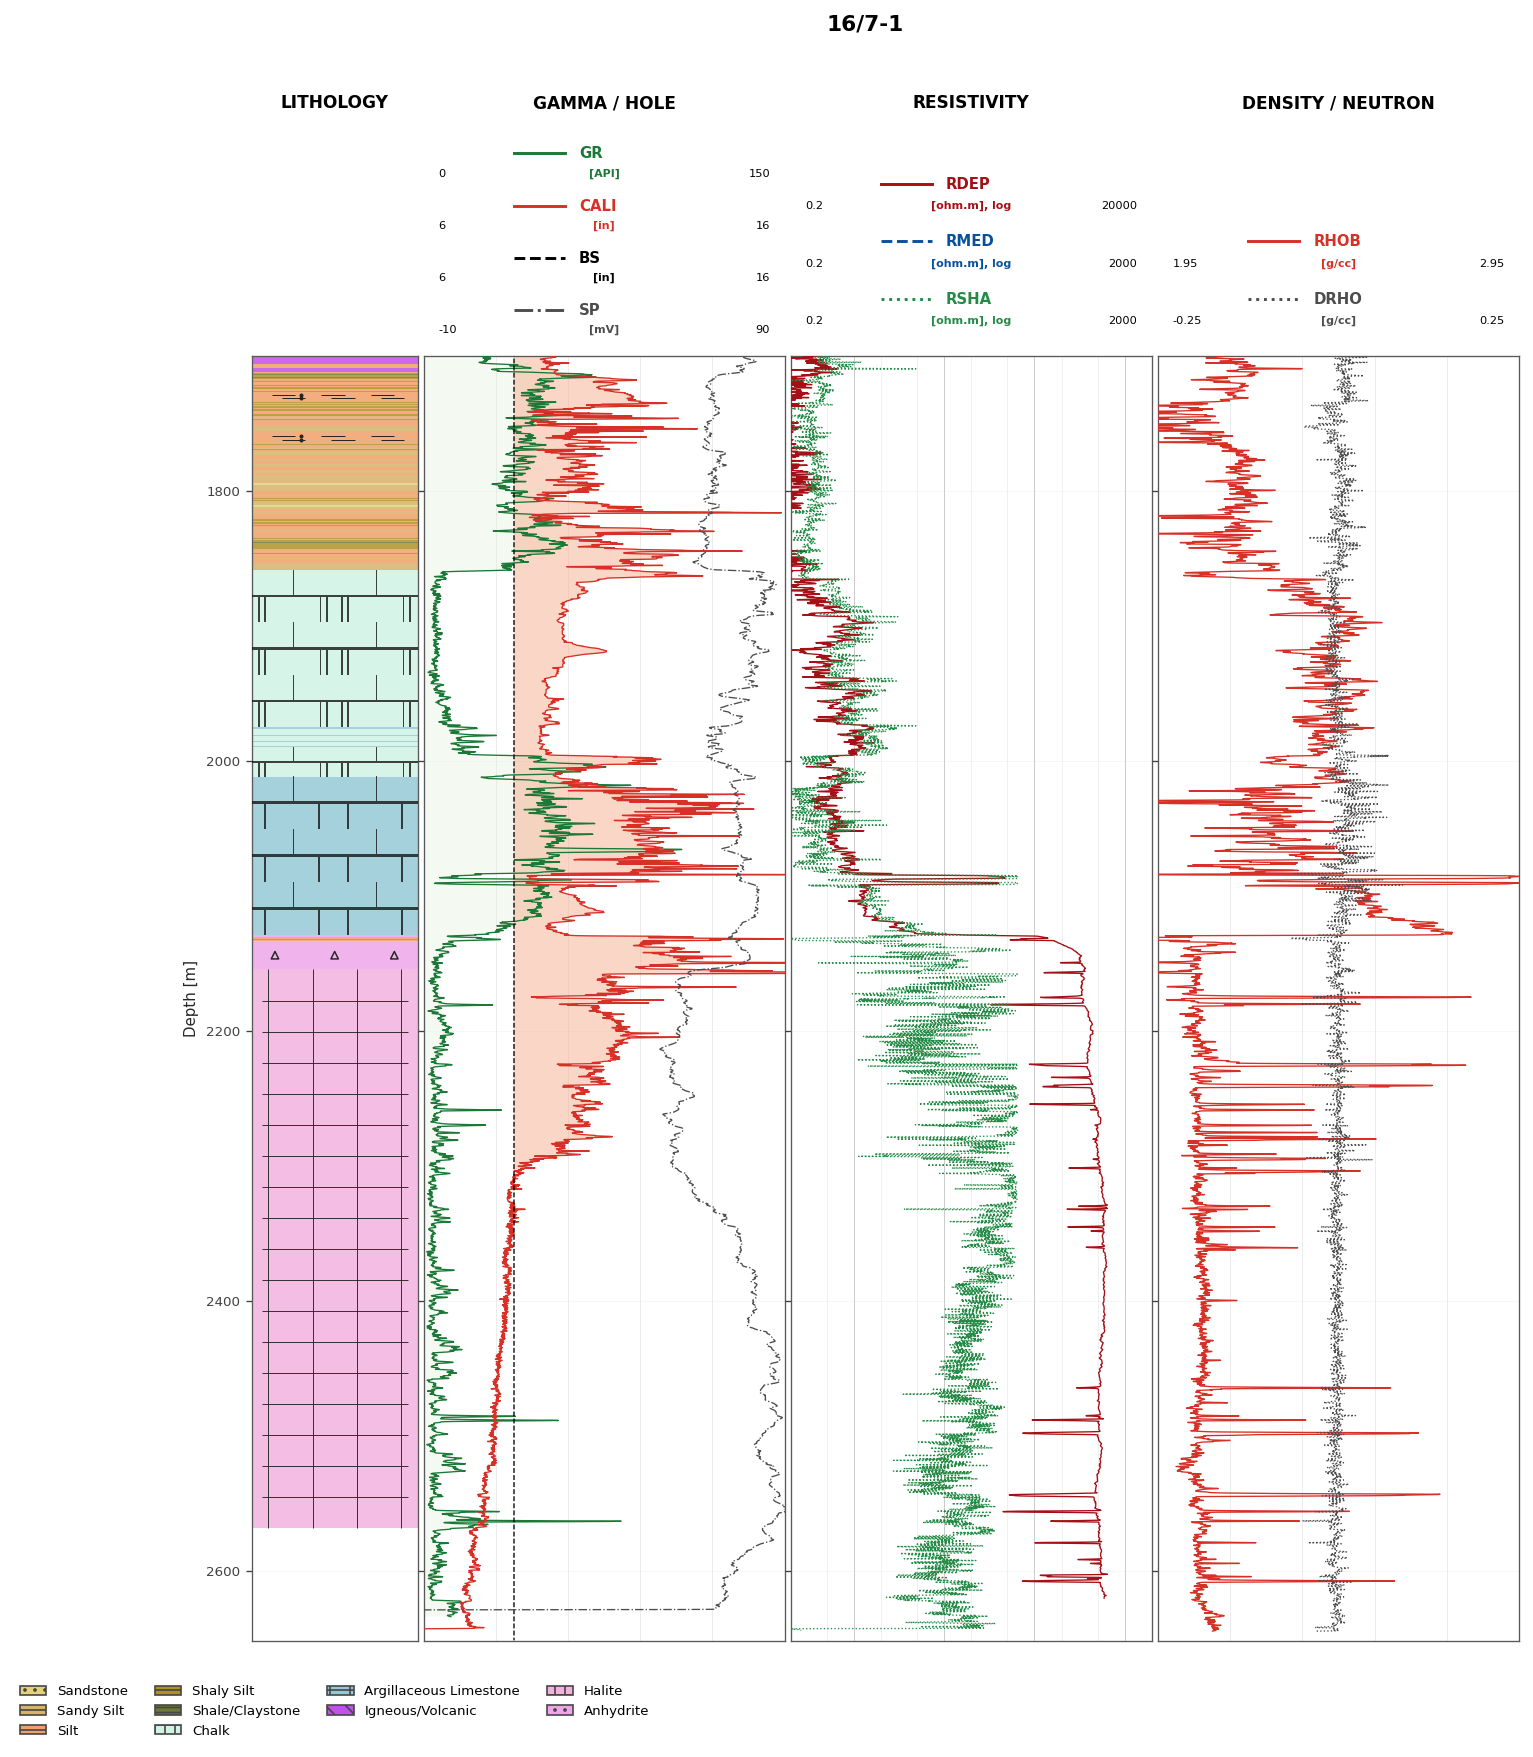

In [9]:
pp.plot(well, top=1700, bottom=2652, tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "DENSITY / NEUTRON"],
        curve_styles={"RDEP": {"right": 20000}}).show()       # widen the RDEP scale to show the plateau

#### QC interpretation

The resistivity was *telling the truth about the rock*. A range cap would remove only the most
extreme samples and leave the rest of the salt in play; the right tool for evaporites is a
**lithology rule** - which is what the interpretation applies (4.6). So the QC above stays a report:
the interpretation runs on the well as logged.

### 4.4 Washout / bad-hole detection

Density (RHOB) is a pad tool - in a washed-out hole the pad loses contact and RHOB reads too
low, inflating density porosity. `detect_washout` flags bad hole from **CALI - BS** (borehole
enlarged beyond bit size) and **|DRHO|** (large density correction).

In [10]:
from petrophys.preprocessing import detect_washout

washout = detect_washout(well)
washout.statistics

{'washout_count': 3920,
 'washout_percent': 26.1577472307487,
 'washout_thickness': 597.4083350000009,
 'large_hole_count': 0,
 'large_hole_percent': 0.0,
 'large_hole_thickness': 0.0,
 'low_density_count': 4411,
 'low_density_percent': 29.434138529294007,
 'low_density_thickness': 672.2370100000023,
 'pef_exclusion_count': 0,
 'pef_exclusion_percent': 0.0,
 'pef_exclusion_thickness': 0.0,
 'bad_hole_count': 3920,
 'bad_hole_percent': 26.1577472307487,
 'bad_hole_thickness': 597.4083350000009}

26% of the hole (597 m) is flagged as washout. That makes three QC findings -
**missing curves**, **resistivity beyond the tool range (evaporites)** and **washout**, plus a
**mis-scaled sonic**. Before interpreting, we test whether the density gaps could be filled.

### 4.5 Testing the imputer on this well

RHOB, the curve the porosity rests on, was only recorded over part of the hole (4.1).
`pp.impute` could fill its gaps: it trains a gradient-boosted tree model on the fly from the other
logs of the well (lesson 13) - here GR, SP, CALI, BS, DRHO, DTC and the three resistivities, since
NPHI and PEF are absent. Before any gap-filled density is used, we need to know how well that model
reproduces *this* well's density.

The professional answer is a **hold-out (blank-and-restore) test**: predict measured density from
a model that never saw it, and compare. `pp.impute` does this by itself. Besides `RHOB_IMPUTED` (the
measured density with its gaps filled) it writes `RHOB_PREDICTED`: a prediction at every depth,
where each measured sample comes from a model trained without its fifth of the well (five
contiguous depth blocks). The curve's description gives the error against the measured density.
We run it on a fresh copy of the well, so the interpreted well stays as logged.

In [11]:
test = pp.impute(pp.read(pp.sample("16_7-1")), "RHOB")
test["RHOB_PREDICTED"].description

[temporary directory]\ipykernel_17472\1619989177.py:1: UserWarning: 16/7-1: 7006 of 7006 imputed RHOB samples have input logs outside the range of the training data, where the model cannot extrapolate
  test = pp.impute(pp.read(pp.sample("16_7-1")), "RHOB")


'RHOB predicted at every depth; at measured depths by a model that did not learn from that part of the well (5 depth blocks): mean absolute error 0.0716 g/cm3, bias -0.0112 g/cm3, R2 0.50 against 7980 measured samples'

Over the 7,980 measured samples the prediction is off by 0.072 g/cm3 on average (mean absolute
error), with R^2 = 0.50. Is that error the model's, or the log's? Split it by the washout flag of 4.4:

In [12]:
error = pd.Series(test["RHOB_PREDICTED"].data - test["RHOB"].data).abs()
error.groupby(washout.bad_hole_flag).agg(["count", "mean"])      # mean absolute error, g/cm3

,count,mean
False,4270,0.059
True,3710,0.086


In washed-out hole (`True`, 3,710 samples) the error is 0.086 g/cm3 - but there the measured RHOB
"truth" is itself suspect (pad off the borehole wall). In gauge (`False`, 4,270 samples) it is
**0.059 g/cm3**, the honest number to carry. On the density-porosity scale (divide by
rho_ma - rho_fl = 2.65 - 1.0 = 1.65 g/cm3) that is about **+/-0.04 v/v** of porosity, on average -
half the 0.08 porosity cutoff. The plot shows where the model follows the density and where it
does not:

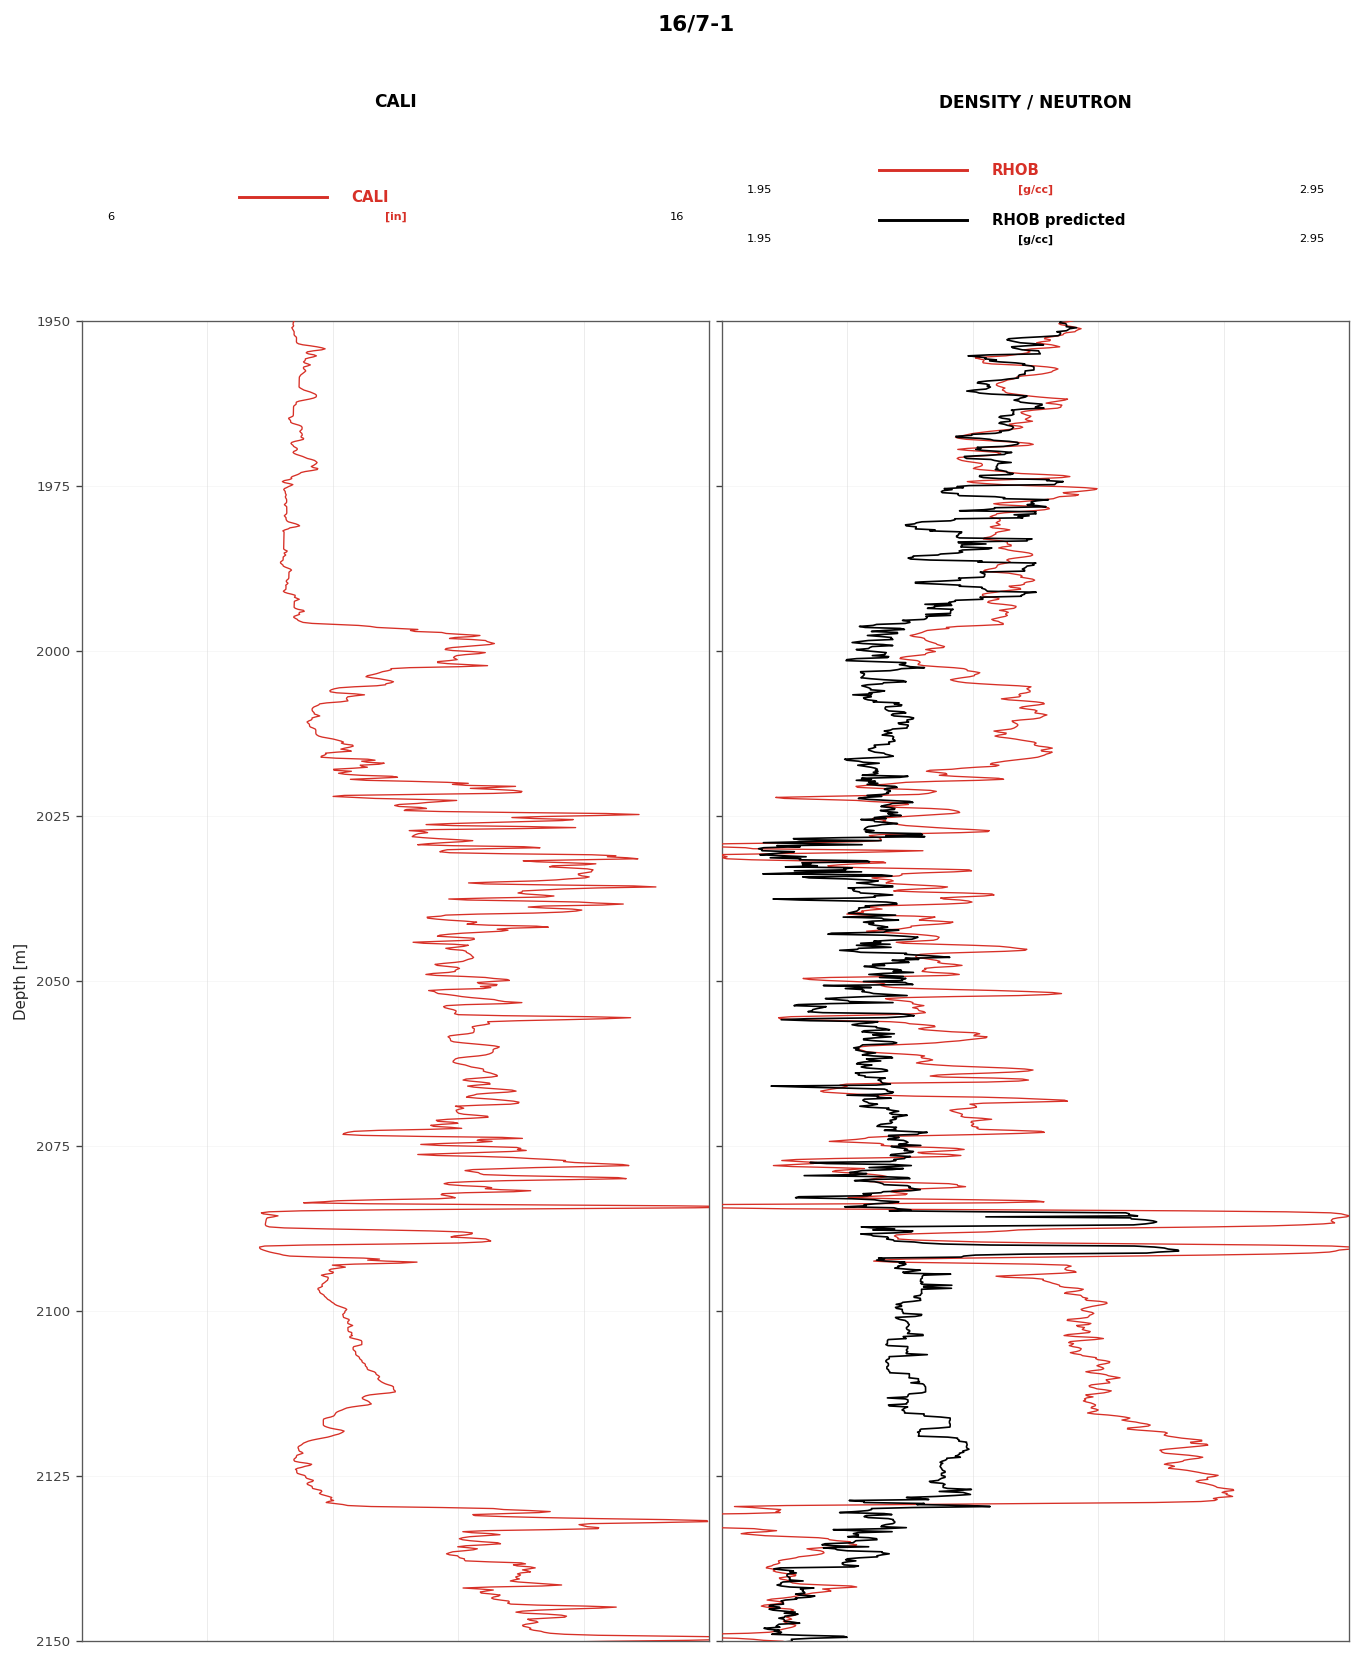

In [13]:
pp.plot(test, curves=["CALI", "RHOB", "RHOB_PREDICTED"], top=1950, bottom=2150).show()

The prediction (black) follows the washed-out section, but in the denser, in-gauge argillaceous
limestone beds (about 2000-2020 m and 2095-2128 m) it reads 0.2-0.3 g/cm3 too light. The imputer
captures the trend but should **not** be treated as a substitute for a real log: good
enough to inform, not good enough to book reserves on. And the gaps it would fill lie outside its
training data: the warning above finds input logs outside the range the model learned from at all
7,006 gap samples (most of the gap is the shallow section the density tool
never logged).

So the evaluation below rests on **measured RHOB only**. The gap-filled `RHOB_IMPUTED` stays on the
test copy, and depths without measured density simply drop out of the pay calculation.

### 4.6 Interpretation on the measured data

`pp.interpret` runs the standard clastic evaluation on the well as logged - Vcl, density porosity
(there is no neutron), Archie-family Sw and net pay - with every assumption passed explicitly so it
is recorded:

- **Rw = 0.05 ohm.m**, assumed (no formation-water sample); given without a temperature, it is taken
  at the median formation temperature.
- **a = 1, m = n = 2**, the textbook Archie constants - assumed.
- the clastic cutoffs `Vcl < 0.40`, `PHIE > 0.08`, `Sw < 0.60`.

The warnings are the second half of the QC report:

In [14]:
ASSUMED = dict(rw=0.05, a=1.0, m=2.0, n=2.0, vcl_cutoff=0.40, phie_cutoff=0.08, sw_cutoff=0.60)
result = pp.interpret(well, **ASSUMED)
result.warnings

[repository]\src\petrophys\workflow\dynamic_workflow.py:5716: DataQualityWarning: DTC: 4914 of 9427 samples are outside the plausible DTC range 38.5 to 300 us/ft and were removed; the other 4513 samples are left out too.
  standardize_curves(


['DTC: 4914 of 9427 samples are outside the plausible DTC range 38.5 to 300 us/ft and were removed; the other 4513 samples are left out too.',
 'No bottom-hole temperature (bht or header BHT): temperatures follow an assumed 30 C/km gradient, which sets the Rw and Rmf temperature corrections.',
 'Rw 0.05 ohm.m was given without rw_meas_temp: it is taken at the median formation temperature, 149.5 degF.',
 'The Rw in use looks too high for this well: over its clean porous rock (VCL < 0.3, porosity > 0.05, 1260 samples) the median apparent water resistivity Rwa = Rt x phi^m / a is 0.48 of it, and Archie gives Sw above 1 at 80% of those samples, where SW is held at 1. Rwa is not below Rw in water-bearing rock, so the formation water is saltier than this Rw implies, or a and m do not fit the rock. Check rw (or salinity_ppm) against a water sample or the water leg.',
 'Irreducible water saturation assumed 0.20 (none could be picked from the logs): PERM, RQI and FZI rest on that value.',
 "Bad

Read them as findings:

- **DTC removed.** 4,914 of the 9,427 DTC samples lie outside the plausible 38.5-300 us/ft range, so
  the workflow drops the whole curve: the mis-scaled sonic of 4.2, caught independently.
- **No BHT.** The header records no bottom-hole temperature, so temperatures follow an assumed
  30 C/km gradient - one more assumption behind the Rw correction.
- **Rw** is taken at the median formation temperature, as intended.
- **Rw looks too high.** In the rock the logs call clean and porous (1,260 samples, most of them the chalk
  at about 1860-2010 m) the apparent water resistivity is about half the assumed Rw, so Archie gives Sw
  above 1 there and the workflow holds it at 1. Either the water is saltier than 0.05 ohm.m implies -
  plausible this close to the Zechstein salt - or a, m and the density porosity do not fit the chalk. A
  lower Rw lowers Sw, so the assumed value errs towards less pay, not more; exercise 2 measures how much.
- **Swirr assumed.** Only the permeability and rock-quality curves rest on the assumed 0.20, and this study
  quotes neither.
- **Bad hole.** The caliper/DRHO flag keeps washed-out samples out of net reservoir and pay -
  2.4 m of pay that the cutoffs alone would have booked.

The porosity and net-pay decisions show what else the workflow left out, and why:

In [15]:
{name: result.step(name).decisions for name in ["porosity", "net_pay"]}

{'porosity': ['Porosity matrix endpoints from the lithology log',
  '418 samples read as halite on the logs (RHOB 1.95-2.15 g/cm3, GR < 15 API, RT > 500 ohm.m or an under-gauge hole) where no lithology group calls them an evaporite: halite endpoints rho_ma 2.032 g/cm3, nphi_ma -0.03, dt_ma 67 us/ft',
  'PHID = (rho_ma(depth) - RHOB) / (rho_ma(depth) - rho_fl)',
  'Density-only porosity: PHIT = PHID because PHIN was unavailable',
  'PHIT written as apparent total porosity (density-derived) because only density porosity (PHID) was available',
  'PHIE written as apparent effective porosity from density-derived PHIT',
  'PHIE = PHIT - VCL * phi_cl (0.150)',
  'Clay porosity phi_cl from the setting or its default, because PHIT clay-porosity control requires neutron-density averaged PHIT samples'],
 'net_pay': ['NET_ROCK: VCL < 0.4 -> 2400 samples (365.8 m)',
  'NET_RES: NET_ROCK and porosity > 0.08 -> 1055 samples (160.8 m); porosity is PHIE, and PHIT at samples without PHIE',
  'NET_PAY: N

**Evaporites.** The workflow leaves rock the lithology log calls salt, anhydrite or gypsum out of net
reservoir and pay (23.3 m of pay here), and tests the halite log response (RHOB 1.95-2.15 g/cm3,
GR < 15 API, RT > 500 ohm.m) where no code says so; evaporites seal reservoirs rather than form them
(Warren, 2006). Halite also gets its own matrix in the porosity step. Coal is left out the same way.

### 4.7 Net pay - with explicit uncertainty flags

Three numbers decompose the answer. The **cutoffs alone** (`summarize_pay`, no exclusions) count
everything that passes Vcl, porosity and Sw. An interpretation that **keeps the washouts**
(`skip_steps=["bad_hole"]`) leaves out only the evaporites and coal. The interpretation above
leaves the washouts out too: its pay is the **firm** pay, and the difference to the second run is
the **uncertain**, washout-flagged pay.

In [16]:
from petrophys.evaluation import summarize_pay

kept_washouts = pp.interpret(well, skip_steps=["bad_hole"], **ASSUMED)
{"cutoffs alone": summarize_pay(result.well, vcl_cutoff=0.40, phie_cutoff=0.08, sw_cutoff=0.60).net_pay_thickness,
 "evaporites and coal left out": kept_washouts.summary()["net_thickness"]["net_pay"],
 "washouts left out too (firm)": result.summary()["net_thickness"]["net_pay"]}

[repository]\src\petrophys\workflow\dynamic_workflow.py:5716: DataQualityWarning: DTC: 4914 of 9427 samples are outside the plausible DTC range 38.5 to 300 us/ft and were removed; the other 4513 samples are left out too.
  standardize_curves(


{'cutoffs alone': 28.651255000000674,
 'evaporites and coal left out': 3.51,
 'washouts left out too (firm)': 1.07}

The cutoffs alone book 28.7 m; leaving out evaporites and coal takes that to 3.5 m, and
leaving out the washouts to **1.1 m of firm pay** - 2.4 m is uncertain, washout-flagged
pay. Where is it, and what rock? First the uncertain run's pay, by logged lithology, then the firm
pay sample by sample:

In [17]:
pay = kept_washouts.well.to_dataframe(["LITHOLOGY_GEOLINK", "NET_PAY"]).query("NET_PAY == 1")
pay.groupby(pay["LITHOLOGY_GEOLINK"].map(LITHOLOGY_CODE_LABELS).fillna("no code"))["DEPTH"].agg(["count", "min", "max"])

,count,min,max
LITHOLOGY_GEOLINK,,,
Argillaceous Limestone,9,2077.108,2129.229
Shaly Silt,5,2132.277,2132.887
Silt,2,2133.039,2133.192
no code,7,2607.003,2608.375


In [18]:
result.well.to_dataframe(["GR", "RHOB", "RDEP", "PHIE", "SW", "LITHOLOGY_GEOLINK", "NET_PAY"]).query("NET_PAY == 1")

,DEPTH,GR,RHOB,RDEP,PHIE,SW,LITHOLOGY_GEOLINK,NET_PAY
14692,2607.003,4.646,2.164,2089.869,0.293,0.014,NaN,1.0
14693,2607.156,4.854,2.236,1072.881,0.249,0.023,NaN,1.0
14694,2607.308,4.606,2.346,719.757,0.183,0.039,NaN,1.0
14695,2607.460,4.866,2.478,532.188,0.102,0.081,NaN,1.0
14699,2608.070,7.081,2.445,396.415,0.119,0.080,NaN,1.0
14700,2608.222,7.096,2.329,556.751,0.189,0.043,NaN,1.0
14701,2608.375,7.229,2.204,1016.665,0.265,0.023,NaN,1.0


The uncertain (washout-flagged) pay is 16 samples of argillaceous limestone, shaly silt and silt at
2077-2133 m, at the top of the Zechstein evaporite section and in washed-out hole. The firm pay is
seven samples at 2607-2608 m with no lithology code: a gamma ray of 5-7 gAPI, deep resistivity of
400-2,100 ohm.m and a density of 2.16-2.48 g/cm3 - between halite (2.03) and anhydrite (2.98), the
response of mixed salt and anhydrite near the base of the well, not of a reservoir. The halite
log-response test does not catch it only because its density is above 2.15 g/cm3.

## 5. Integrated result - the interpretation plot

The summary figure is the heart of the deliverable: the interpretation panel over the lower part of
the well, with the vendor lithology, the washout (BADHOLE) shading on every track and the net-pay
flags, so a reviewer can see at a glance where the answer is firm and where it is not. The porosity and
permeability that run off scale at about 2130-2155 m are the anhydrite in washed-out hole, where the density
pad reads mud: the bad-hole shading covers them and the evaporite rule keeps them out of every number.

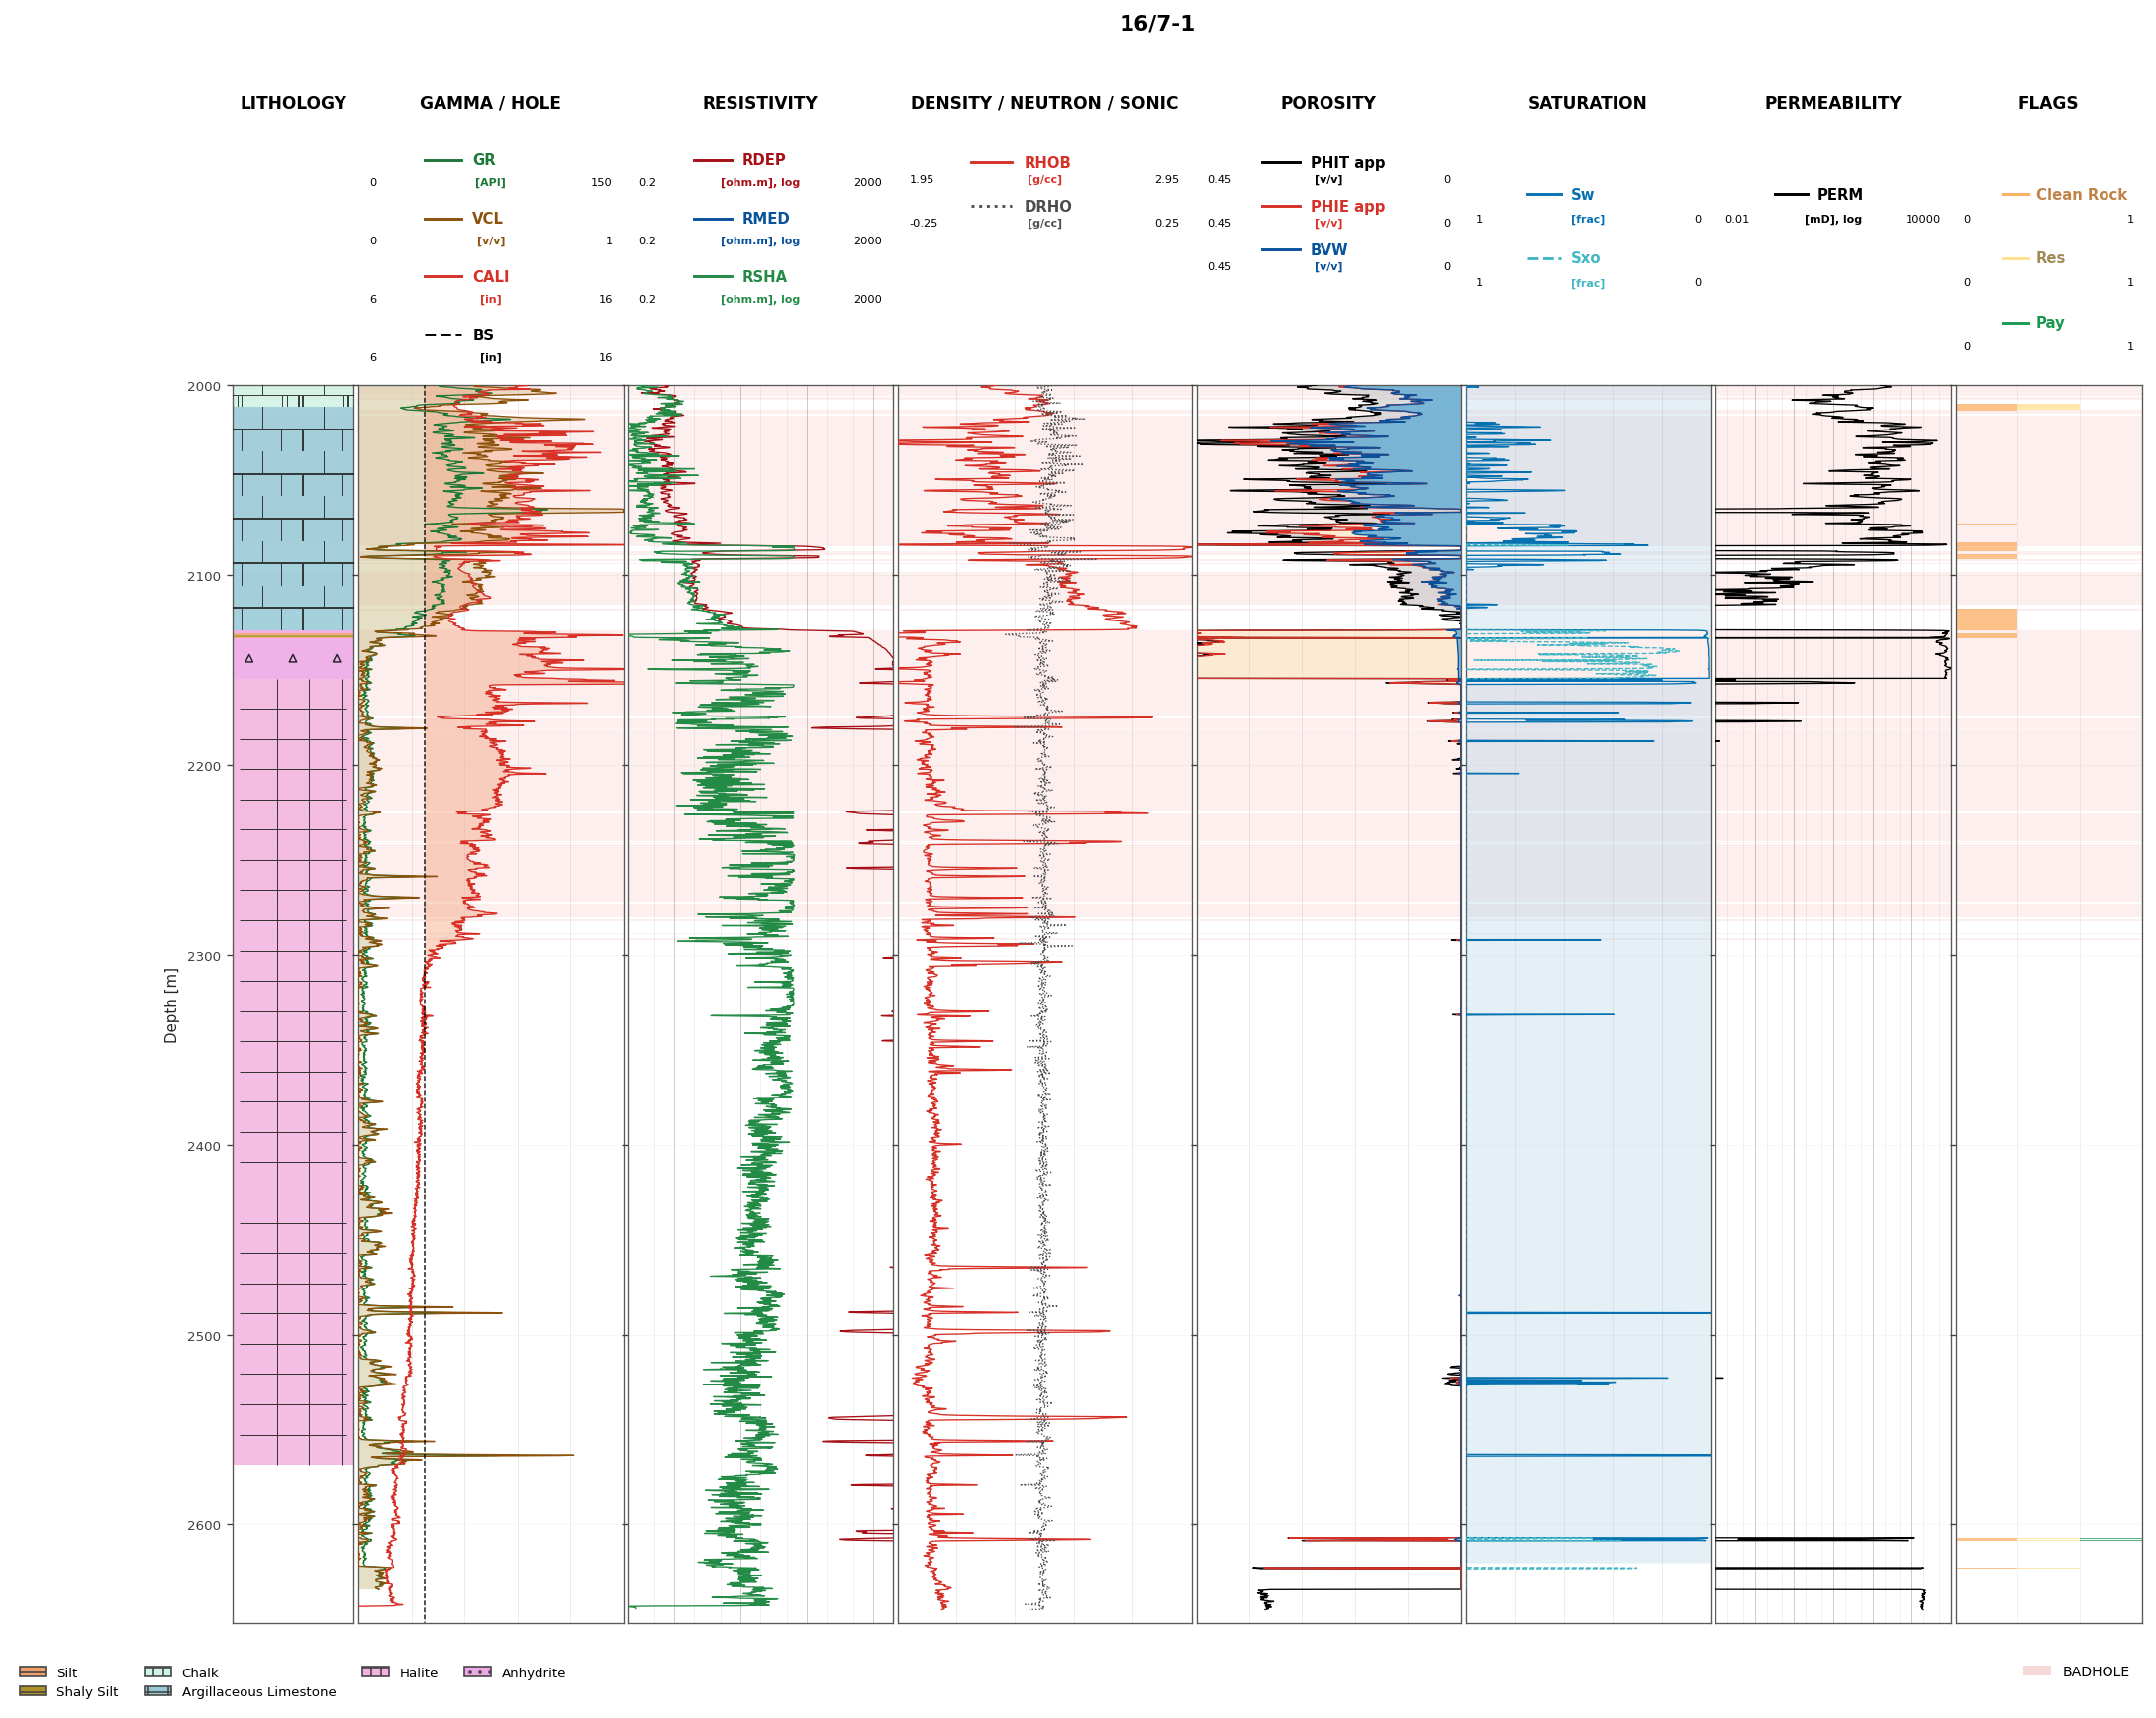

In [19]:
pp.plot(result, top=2000, bottom=2652, template="petrophysics").show()

## 6. Interpretation & deliverable

### 6.1 The data readiness report (measured, flagged, missing)

The auditable core of the deliverable - curve by curve, what came from the tool string, what was
flagged and what is missing:

| Curve | Source | Coverage | Role | Trust |
|---|---|---|---|---|
| GR | measured | 99% | Vcl (primary), imputer input | HIGH |
| CALI / BS / DCAL | measured | 100% | washout / bad-hole QC | HIGH |
| RHOB | measured (partial) | 53% | the only porosity log | MEDIUM (26% of the hole washout-flagged) |
| DTC | measured (partial) | 63% | imputer input; dropped by the interpretation | LOW (mis-scaled, about 0.31 times the expected values) |
| RDEP | measured | 99% | Sw | MEDIUM (> 2000 ohm.m in the evaporites, which are left out) |
| SP | measured | 100% | Vcl (reported) | MEDIUM (136 impossible spikes) |
| NPHI | missing | 0% | neutron-density porosity (not attempted) | N/A |
| PEF | missing | 0% | lithology (not attempted) | N/A |

### 6.2 The caveated result

**Recommendation to management (honest version):**

- 16/7-1 supports a **defensible but uncertainty-bounded** interpretation, and its finding is
  negative. The cutoffs alone would book 28.7 m of pay, almost all of it salt: the
  interpretation leaves the evaporites out and keeps 3.5 m, of which 2.4 m sits in
  washout-flagged hole where the pad-tool density (hence porosity) is suspect.
- The **firm** pay - measured density, in-gauge hole - is 1.1 m, and it is not reservoir
  either: very low GR, deep resistivity in the hundreds to thousands of ohm.m and no lithology code,
  in the uncoded salt near the base of the well. The NPD fact page reports 16/7-1 as a dry well with
  no shows. **On today's data the well has no pay to book.**
- Two things a reviewer should see stated plainly. First, intervals with **no measured density**
  are not in the pay number at all - PHIE is NaN there, so they fail the cutoffs by construction.
  Second, **no curve in the pay number is modelled** - PHIE rests on measured density alone, since
  the well has no neutron log and the imputer test (4.5) is not good enough to fill the density gaps.
- **Before reusing this well**, (a) acquire a formation-water sample to replace the assumed $R_w$;
  (b) fix or re-acquire the sonic, which is stored on the wrong scale; (c) repeat the density over the
  un-logged and washed-out intervals; and (d) extend the lithology log to the uncoded base of the
  well. No new resistivity log is needed: the >2000 ohm.m readings are the salt.

The value of this workflow is not that it invented data - it is that it made the well *usable*
today while drawing a bright, auditable line between what we measured, what we flagged and what we
assumed, and it found the lithology behind the most alarming-looking curve.

## 7. Limitations & assumptions

An honest study lists its own weak points:

1. **No neutron log.** NPHI is missing and is not rebuilt. Rebuilding a neutron log for this well
   would need training wells from a field that drilled the same evaporites, and the bundled wells
   did not, so none is built. Porosity rests on density alone.
2. **DTC is mis-scaled** (about 0.31 times the expected values, 4.2). The interpretation drops it, but
   it was still an imputer input, so the hold-out errors (4.5) are contaminated by it.
3. **$R_w$ is assumed** (0.05 ohm.m at the median formation temperature), and so is the temperature
   gradient (no BHT). No formation-water sample, and the workflow's own check reads the assumed value as too
   high for the chalk (4.6). Sw scales roughly with $\sqrt{R_w}$, so a 2x error
   in $R_w$ moves Sw by ~40%.
4. **Archie exponents $a,m,n$ are textbook defaults** - no core-derived $m$/$n$ (unlike CS2).
5. **RDEP above 2000 ohm.m is kept, not corrected** - the evaporites it marks are left out of pay by
   lithology, not by a resistivity cap.
6. **PEF is missing** and, for the same reason as NPHI, not rebuilt, so the lithology rests on the
   vendor log and the halite log-response test.
7. **No core, no formation tops** were used - this is a stand-alone log evaluation.
8. **The lithology log has gaps.** Uncoded rock is judged on its log response only; the firm pay is
   in such rock (6.2).

Items 1-4 and 6 need new or corrected data (section 6.2); items 5 and 8 rest on the lithology log
the well already carries.

## 8. Appendix - reproduce on another well

The recovery workflow is well-agnostic. To run it on another LAS with a similar curve suite:

```python
well = pp.read("<your_file.las>")                       # or pp.sample("15_9-14"), "25_5-1", ...
pd.DataFrame(well.describe()["curves"])                 # 1. readiness
well.to_dataframe().describe().T                        #    and value ranges
detect_washout(well).statistics                         # 2. washout
result = pp.interpret(well, rw=..., rw_meas_temp=...) # 3. interpret, assumptions stated
result.warnings                                         #    the QC findings
pp.interpret(well, skip_steps=["bad_hole"], rw=...)     # 4. the washout-flagged (uncertain) pay
```

and check any gap-filled curve against its hold-out prediction (`<CURVE>_PREDICTED`, 4.5) before it
goes near a cutoff.

**Key API reminders learned in this study:**
- `pp.impute(well, curve)` fills the null samples of a curve into a new `<CURVE>_IMPUTED`; the
  measured samples are kept exactly and the original curve is untouched.
- `pp.impute` warns when imputed samples have input logs outside the range of the training data.
  Read the count, and find out which input causes it.
- `pp.interpret` screens implausible values (here the sonic and the SP spikes) with a warning, leaves
  evaporites, coal and bad hole out of net reservoir and pay, and says how much pay each removed.

### Where this sits in the curriculum
CS4 completes the robustness arc: CS1 (full evaluation), CS2 (carbonate + core), CS3 (multiwell
screening), **CS4 (imperfect-data robustness)**, and CS5 (saturation-model sensitivity).

### Recap

- A **data-readiness table** shows what is missing (NPHI, PEF) and what is only partly recorded
  before any interpretation starts, and the value ranges show what is implausible.
- **Out-of-range resistivity and washouts are flagged**, not silently corrected, and the cause is
  checked: the >2000 ohm.m readings are the evaporite section, not a tool fault. The sonic is on
  the wrong scale and is rated LOW; the interpretation drops it too.
- The imputer is **validated by a hold-out prediction** of the measured density, and the error
  is split by hole condition: the in-gauge error is the honest number to carry.
- The evaluation rests on **measured curves only**: no neutron log is rebuilt, and the gap-filled
  density stays out of the pay number.
- The deliverable is **firm vs uncertain net pay** plus a curve-by-curve readiness report - and a
  **lithology cross-check**: the pay the cutoffs alone would book is salt, not reservoir.

### Exercises

1. **Training wells.** Re-run `pp.impute` on the test copy with
   `train_wells=[pp.sample("15_9-14"), pp.sample("25_5-1")]`. Does the in-gauge error fall?
2. **Rw sensitivity.** Re-run the pay split with `rw=0.025` (about what the clean rock implies, 4.6) and `rw=0.08`. How much of the firm pay
   survives?
3. **Without the mis-scaled sonic.** Remove DTC from the test copy before imputing
   (`well.remove_curve("DTC")`; `pp.impute` uses only the inputs a well has). Does the in-gauge
   error improve?
4. **Washout thresholds.** Re-run with `bad_hole={"cali": 3.0}`. How much of the uncertain pay
   becomes firm, and would you accept it?

### What's next

**CS5** - saturation-model selection and parameter sensitivity on well 30/6-5.